In [1]:
%pip install opencv-python-headless
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import os
import cv2
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import random


[notice] A new release of pip is available: 24.1.2 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


2026-10-26 03:47:59.829087: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-26 03:47:59.857132: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792986479.883106    2872 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792986479.889517    2872 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792986479.916334    2872 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
gpus= tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"Error configurando GPI: {e}")

In [3]:
def gradient_loss(y_true, y_pred):
    """
    Calcula la pérdida basada en gradientes para preservar edges y detalles
    """
    # Calcular gradientes en X e Y
    def get_gradients(img):
        # Gradientes horizontales
        grad_x = img[:, :, 1:, :] - img[:, :, :-1, :]
        # Gradientes verticales  
        grad_y = img[:, 1:, :, :] - img[:, :-1, :, :]
        return grad_x, grad_y
    
    # Gradientes de imágenes verdaderas
    true_grad_x, true_grad_y = get_gradients(y_true)
    # Gradientes de predicciones
    pred_grad_x, pred_grad_y = get_gradients(y_pred)
    
    # Pérdida L1 en gradientes
    grad_loss_x = tf.reduce_mean(tf.abs(true_grad_x - pred_grad_x))
    grad_loss_y = tf.reduce_mean(tf.abs(true_grad_y - pred_grad_y))
    
    return grad_loss_x + grad_loss_y

def combined_loss(y_true, y_pred):
    """
    Función de pérdida combinada: MSE + Gradient Loss
    """
    # Pérdida MSE tradicional
    mse_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    # Pérdida de gradientes para preservar detalles
    grad_loss = gradient_loss(y_true, y_pred)
    
    # Combinar pérdidas (puedes ajustar los pesos)
    total_loss = mse_loss + 0.1 * grad_loss
    
    return total_loss

In [4]:
class COIL100RotationPredictor:
    def __init__(self, data_path, img_size=(128, 128)):
        self.data_path = data_path
        self.img_size = img_size
        self.sequence_length = 4
        self.model = None
        
        # Objetos para validación (5 objetos aleatorios)
        all_objects = list(range(1, 101))  # obj1 to obj100
        self.validation_objects = random.sample(all_objects, 10)
        self.train_objects = [obj for obj in all_objects if obj not in self.validation_objects]
        
        print(f"Objetos de entrenamiento: {len(self.train_objects)} objetos")
        print(f"Objetos de validación: {self.validation_objects}")
    
    def load_object_images(self, obj_num):
        """Carga las 72 imágenes de un objeto específico"""
        images = []
        missing_files = []
        
        for angle in range(0, 360, 5):  # 0, 5, 10, ..., 355
            # Probar diferentes formatos de nombre de archivo
            possible_names = [
                f"obj{obj_num}__{angle}.png",
                f"obj{obj_num:02d}__{angle}.png",  # con ceros a la izquierda
                f"obj{obj_num}__{angle:03d}.png",  # ángulo con 3 dígitos
                f"obj{obj_num:02d}__{angle:03d}.png"  # ambos con ceros
            ]
            
            image_loaded = False
            for img_name in possible_names:
                img_path = os.path.join(self.data_path, img_name)
                if os.path.exists(img_path):
                    try:
                        img = cv2.imread(img_path)
                        if img is not None:
                            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                            img = cv2.resize(img, self.img_size)
                            img = img.astype(np.float32) / 255.0  # Normalizar
                            images.append(img)
                            image_loaded = True
                            break
                    except Exception as e:
                        print(f"Error cargando {img_path}: {e}")
            
            if not image_loaded:
                missing_files.append(f"angle {angle}")
        
        if missing_files and len(missing_files) < 10:  # Mostrar algunos archivos faltantes
            print(f"  - Archivos faltantes para objeto {obj_num}: {missing_files[:5]}...")
        
        return np.array(images)
    
    def create_sequences(self, images, num_sequences_per_object=20):
        """
        Crea secuencias aleatorias de 4 imágenes + 1 target
        Para cada objeto, genera múltiples secuencias aleatorias.
        Permite wrap-around: si la secuencia llega al final, continúa desde el inicio.
        Garantiza que no haya ángulos de inicio duplicados.
        """
        X, y = [], []
        num_images = len(images)
        
        # *** EVITAR DUPLICADOS: Seleccionar índices únicos ***
        if num_sequences_per_object >= num_images:
            # Si pedimos más secuencias que imágenes disponibles, usar todas
            selected_indices = list(range(num_images))
            print(f"  - Advertencia: Solicitadas {num_sequences_per_object} secuencias, pero solo hay {num_images} ángulos. Usando todos.")
        else:
            # Seleccionar aleatoriamente sin repetición
            selected_indices = random.sample(range(num_images), num_sequences_per_object)
        
        for start_idx in selected_indices:
            # Crear secuencia de 4 imágenes con wrap-around
            sequence = []
            step_aleatorio = random.randint(1, 5)
            for i in range(4):
                idx = (start_idx + i*step_aleatorio) % num_images  # Módulo para wrap-around
                sequence.append(images[idx])
            
            # Target: la quinta imagen (también con wrap-around)
            target_idx = (start_idx + 4*step_aleatorio) % num_images
            target = images[target_idx]
            
            X.append(np.array(sequence))
            y.append(target)
            
        return np.array(X), np.array(y)
    
    def prepare_dataset(self, num_sequences_per_object=20):
        """Prepara el dataset completo"""
        print("Preparando dataset...")
        print(f"Ruta de datos: {self.data_path}")
        
        # Verificar que la ruta existe
        if not os.path.exists(self.data_path):
            raise FileNotFoundError(f"La ruta {self.data_path} no existe")
        
        # Listar algunos archivos para verificar el formato
        files = os.listdir(self.data_path)
        print(f"Archivos encontrados: {len(files)}")
        if len(files) > 0:
            print(f"Ejemplos de archivos: {files[:5]}")
        
        # Dataset de entrenamiento
        X_train_list, y_train_list = [], []
        successful_train_objects = 0
        
        for obj_num in self.train_objects:
            print(f"Procesando objeto {obj_num} (entrenamiento)...")
            images = self.load_object_images(obj_num)
            print(f"  - Imágenes cargadas: {len(images)}")
            
            if len(images) == 72:  # Verificar que se cargaron todas las imágenes
                X_seq, y_seq = self.create_sequences(images, num_sequences_per_object)
                X_train_list.append(X_seq)
                y_train_list.append(y_seq)
                successful_train_objects += 1
                print(f"  - ✓ Secuencias creadas: {X_seq.shape[0]}")
            else:
                print(f"  - ✗ Error: Se esperaban 72 imágenes, se encontraron {len(images)}")
        
        # Dataset de validación
        X_val_list, y_val_list = [], []
        successful_val_objects = 0
        
        for obj_num in self.validation_objects:
            print(f"Procesando objeto {obj_num} (validación)...")
            images = self.load_object_images(obj_num)
            print(f"  - Imágenes cargadas: {len(images)}")
            
            if len(images) == 72:
                X_seq, y_seq = self.create_sequences(images, num_sequences_per_object)
                X_val_list.append(X_seq)
                y_val_list.append(y_seq)
                successful_val_objects += 1
                print(f"  - ✓ Secuencias creadas: {X_seq.shape[0]}")
            else:
                print(f"  - ✗ Error: Se esperaban 72 imágenes, se encontraron {len(images)}")
        
        # Verificar que tenemos datos antes de concatenar
        if len(X_train_list) == 0:
            raise ValueError("No se pudieron cargar datos de entrenamiento. Verifica la ruta y el formato de archivos.")
        if len(X_val_list) == 0:
            raise ValueError("No se pudieron cargar datos de validación. Verifica la ruta y el formato de archivos.")
        
        # Concatenar todos los datos
        self.X_train = np.concatenate(X_train_list, axis=0)
        self.y_train = np.concatenate(y_train_list, axis=0)
        self.X_val = np.concatenate(X_val_list, axis=0)
        self.y_val = np.concatenate(y_val_list, axis=0)
        
        print(f"\n✓ Dataset preparado exitosamente:")
        print(f"- Objetos de entrenamiento procesados: {successful_train_objects}/{len(self.train_objects)}")
        print(f"- Objetos de validación procesados: {successful_val_objects}/{len(self.validation_objects)}")
        print(f"- Entrenamiento: {self.X_train.shape[0]} secuencias")
        print(f"- Validación: {self.X_val.shape[0]} secuencias")
        print(f"- Shape de secuencia: {self.X_train.shape[1:]}")
        print(f"- Shape de target: {self.y_train.shape[1:]}")
    
    def build_model(self, use_combined_loss=True):
        """Construye el modelo ConvLSTM para predicción"""
        model = models.Sequential([
            # Capa de entrada explícita
            layers.Input(shape=(self.sequence_length, *self.img_size, 3)),
            
            # Capas convolucionales con TimeDistributed
            layers.TimeDistributed(
                layers.Conv2D(32, (3, 3), activation='relu', padding='same')
            ),
            layers.TimeDistributed(layers.MaxPooling2D((2, 2))),
            layers.TimeDistributed(layers.Conv2D(64, (3, 3), activation='relu', padding='same')),
            layers.TimeDistributed(layers.MaxPooling2D((2, 2))),
            
            # ConvLSTM para capturar dependencias temporales
            layers.ConvLSTM2D(
                filters=64, 
                kernel_size=(3, 3),
                activation='tanh',
                padding='same',
                return_sequences=False  # Solo necesitamos la última salida
            ),
            
            # Decoder para generar la imagen siguiente
            layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
            layers.UpSampling2D((2, 2)),
            layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
            layers.UpSampling2D((2, 2)),
            layers.Conv2D(3, (3, 3), activation='sigmoid', padding='same')  # Salida RGB
        ])
        
        # Seleccionar función de pérdida
        if use_combined_loss:
            loss_function = combined_loss
            print("✓ Usando combined_loss (MSE + Gradient Loss)")
        else:
            loss_function = 'mse'
            print("✓ Usando MSE tradicional")
        
        model.compile(
            optimizer='adam',
            loss=loss_function,
            metrics=['mae']
        )
        
        self.model = model
        return model
    
    def train_model(self, epochs=50, batch_size=16):
        """Entrena el modelo"""
        if self.model is None:
            raise ValueError("Modelo no construido. Llama a build_model() primero.")
        
        # Callbacks
        callbacks = [
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=5, verbose=1
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss', patience=20, restore_best_weights=True
            )
        ]
        
        # Entrenamiento
        history = self.model.fit(
            self.X_train, self.y_train,
            batch_size=batch_size,
            epochs=epochs,
            validation_data=(self.X_val, self.y_val),
            callbacks=callbacks,
            verbose=1
        )
        
        return history
    
    def predict_next_frame(self, sequence):
        """Predice la siguiente imagen dada una secuencia de 4"""
        if len(sequence.shape) == 4:  # Si es una sola secuencia
            sequence = np.expand_dims(sequence, axis=0)
        
        prediction = self.model.predict(sequence)
        return prediction[0] if len(prediction) == 1 else prediction
    
    def visualize_prediction(self, obj_num, start_angle=0, step_ang=1):
        """Visualiza una predicción específica, 
        start_angle multiplo de 5 entre 0 y 355, step_ang numero entero entre 1 y 4"""
        # Cargar imágenes del objeto
        images = self.load_object_images(obj_num)
        
        # Crear secuencia con wrap-around
        start_idx = start_angle // 5  # Convertir ángulo a índice
        
        # Crear secuencia usando la misma lógica que create_sequences
        sequence = []
        angles = []
        for i in range(4):
            idx = (start_idx + i*step_ang) % len(images)
            sequence.append(images[idx])
            angles.append((start_angle + i*5*step_ang) % 360)
        
        # Target con wrap-around
        target_idx = (start_idx + 4*step_ang) % len(images)
        true_next = images[target_idx]
        target_angle = (start_angle + 20*step_ang) % 360
        
        sequence = np.array(sequence)
        
        # Predecir
        pred_next = self.predict_next_frame(sequence)
        
        # Visualizar - Corregir el grid de subplots
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))  # 2 filas × 4 columnas
        
        # Primera fila: Secuencia de entrada (4 imágenes)
        for i in range(4):
            axes[0, i].imshow(sequence[i])
            axes[0, i].set_title(f'Input {i+1}\nAngle: {angles[i]}°')
            axes[0, i].axis('off')
        
        # Segunda fila: Resultados
        # Verdadera siguiente imagen
        axes[1, 0].imshow(true_next)
        axes[1, 0].set_title(f'True Next\nAngle: {target_angle}°')
        axes[1, 0].axis('off')
        
        # Predicción
        axes[1, 1].imshow(pred_next)
        axes[1, 1].set_title('Predicted Next')
        axes[1, 1].axis('off')
        
        # Diferencia absoluta
        diff = np.abs(true_next - pred_next)
        axes[1, 2].imshow(diff)
        axes[1, 2].set_title('Absolute Difference')
        axes[1, 2].axis('off')
        
        # MSE como texto en la última celda
        mse = np.mean((true_next - pred_next) ** 2)
        axes[1, 3].text(0.5, 0.5, f'MSE: {mse:.4f}\n\nObject: {obj_num}\nStart angle: {start_angle}°\nStep: {5*step_ang}°', 
                       horizontalalignment='center', verticalalignment='center', 
                       transform=axes[1, 3].transAxes, fontsize=12,
                       bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
        axes[1, 3].axis('off')
        
        plt.tight_layout()
        plt.show()


In [5]:
if __name__ == "__main__":
    # Inicializar
    data_path = "./coil-100"
    predictor = COIL100RotationPredictor(data_path)
    
    # Preparar datos
    predictor.prepare_dataset(num_sequences_per_object=36)


Objetos de entrenamiento: 90 objetos
Objetos de validación: [93, 74, 43, 96, 23, 98, 87, 83, 14, 46]
Preparando dataset...
Ruta de datos: ./coil-100
Archivos encontrados: 7202
Ejemplos de archivos: ['convertGroupppm2png.pl', 'convertGroupppm2png.pl~', 'obj100__0.png', 'obj100__10.png', 'obj100__100.png']
Procesando objeto 1 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 2 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 3 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 4 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 5 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 6 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 7 (entrenamiento)...
  - Imágenes cargadas: 72
  - ✓ Secuencias creadas: 36
Procesando objeto 8 (entrenamiento).

In [6]:
    # Construir y entrenar modelo
    model = predictor.build_model(use_combined_loss=True)  # True para combined_loss, False para MSE tradicional
    print(model.summary())
    
    # Entrenar
    history = predictor.train_model(epochs=80, batch_size=4)

I0000 00:00:1792986745.623302    2872 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3620 MB memory:  -> device: 0, name: NVIDIA RTX A1000 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


✓ Usando combined_loss (MSE + Gradient Loss)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, 4, 128, 128,    │           896 │
│ (TimeDistributed)               │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 4, 64, 64, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 4, 64, 64, 64)  │        18,496 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 4, 32, 32, 64)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d (ConvLSTM2D)        │ (None, 32, 32, 64)     │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 370,819 (1.41 MB)

 Trainable params: 370,819 (1.41 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/80


I0000 00:00:1792986763.305748    3061 service.cc:152] XLA service 0x7815fc0d4340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792986763.305892    3061 service.cc:160]   StreamExecutor device (0): NVIDIA RTX A1000 6GB Laptop GPU, Compute Capability 8.6
2026-10-26 03:52:43.475621: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792986764.469028    3061 cuda_dnn.cc:529] Loaded cuDNN version 90501
I0000 00:00:1792986773.205545    3061 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


810/810 ━━━━━━━━━━━━━━━━━━━━ 47s 39ms/step - loss: 0.0238 - mae: 0.0900 - val_loss: 0.0146 - val_mae: 0.0599 - learning_rate: 0.0010
Epoch 2/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - loss: 0.0126 - mae: 0.0550 - val_loss: 0.0143 - val_mae: 0.0610 - learning_rate: 0.0010
Epoch 3/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - loss: 0.0113 - mae: 0.0506 - val_loss: 0.0132 - val_mae: 0.0541 - learning_rate: 0.0010
Epoch 4/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - loss: 0.0109 - mae: 0.0485 - val_loss: 0.0128 - val_mae: 0.0525 - learning_rate: 0.0010
Epoch 5/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - loss: 0.0105 - mae: 0.0472 - val_loss: 0.0125 - val_mae: 0.0500 - learning_rate: 0.0010
Epoch 6/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 26s 32ms/step - loss: 0.0102 - mae: 0.0461 - val_loss: 0.0120 - val_mae: 0.0493 - learning_rate: 0.0010
Epoch 7/80
810/810 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step - loss: 0.0105 - mae: 0.0474 - val_loss: 0.0124 - val_mae: 0.0551 - learning_rate: 0.0010
Epo

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


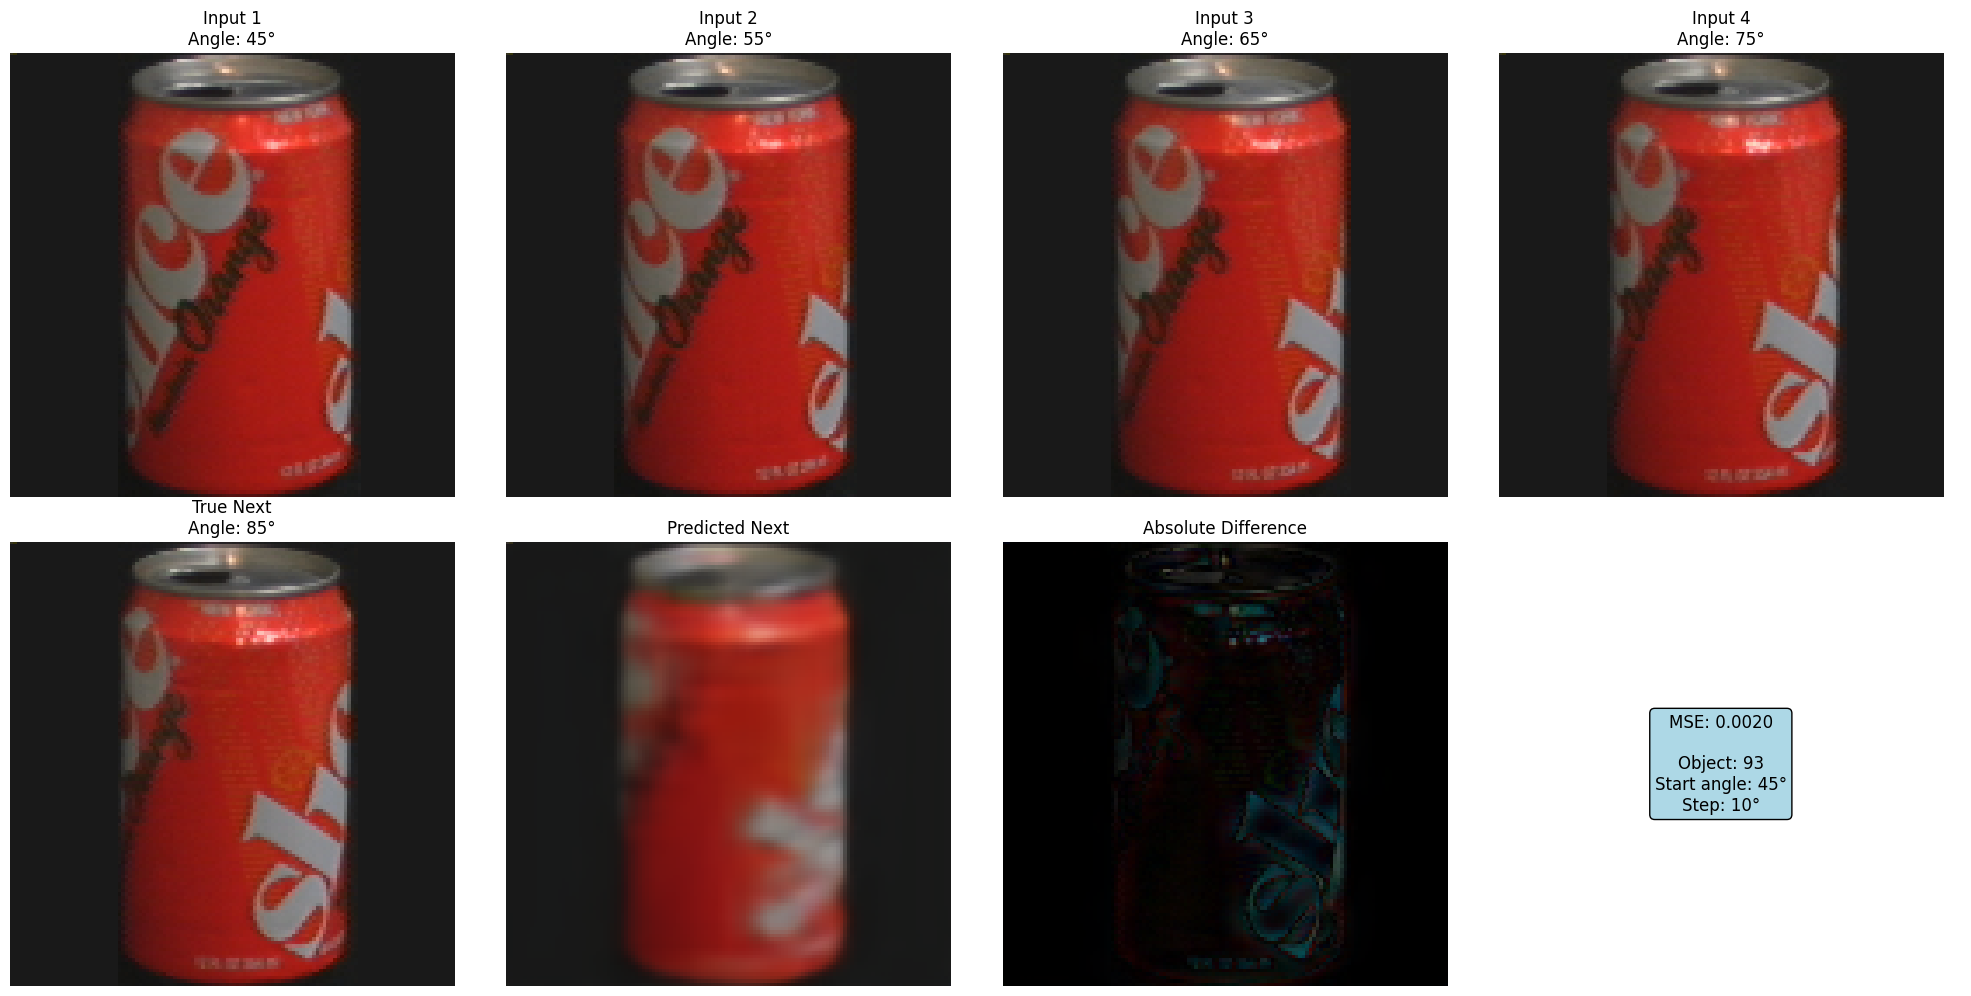

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


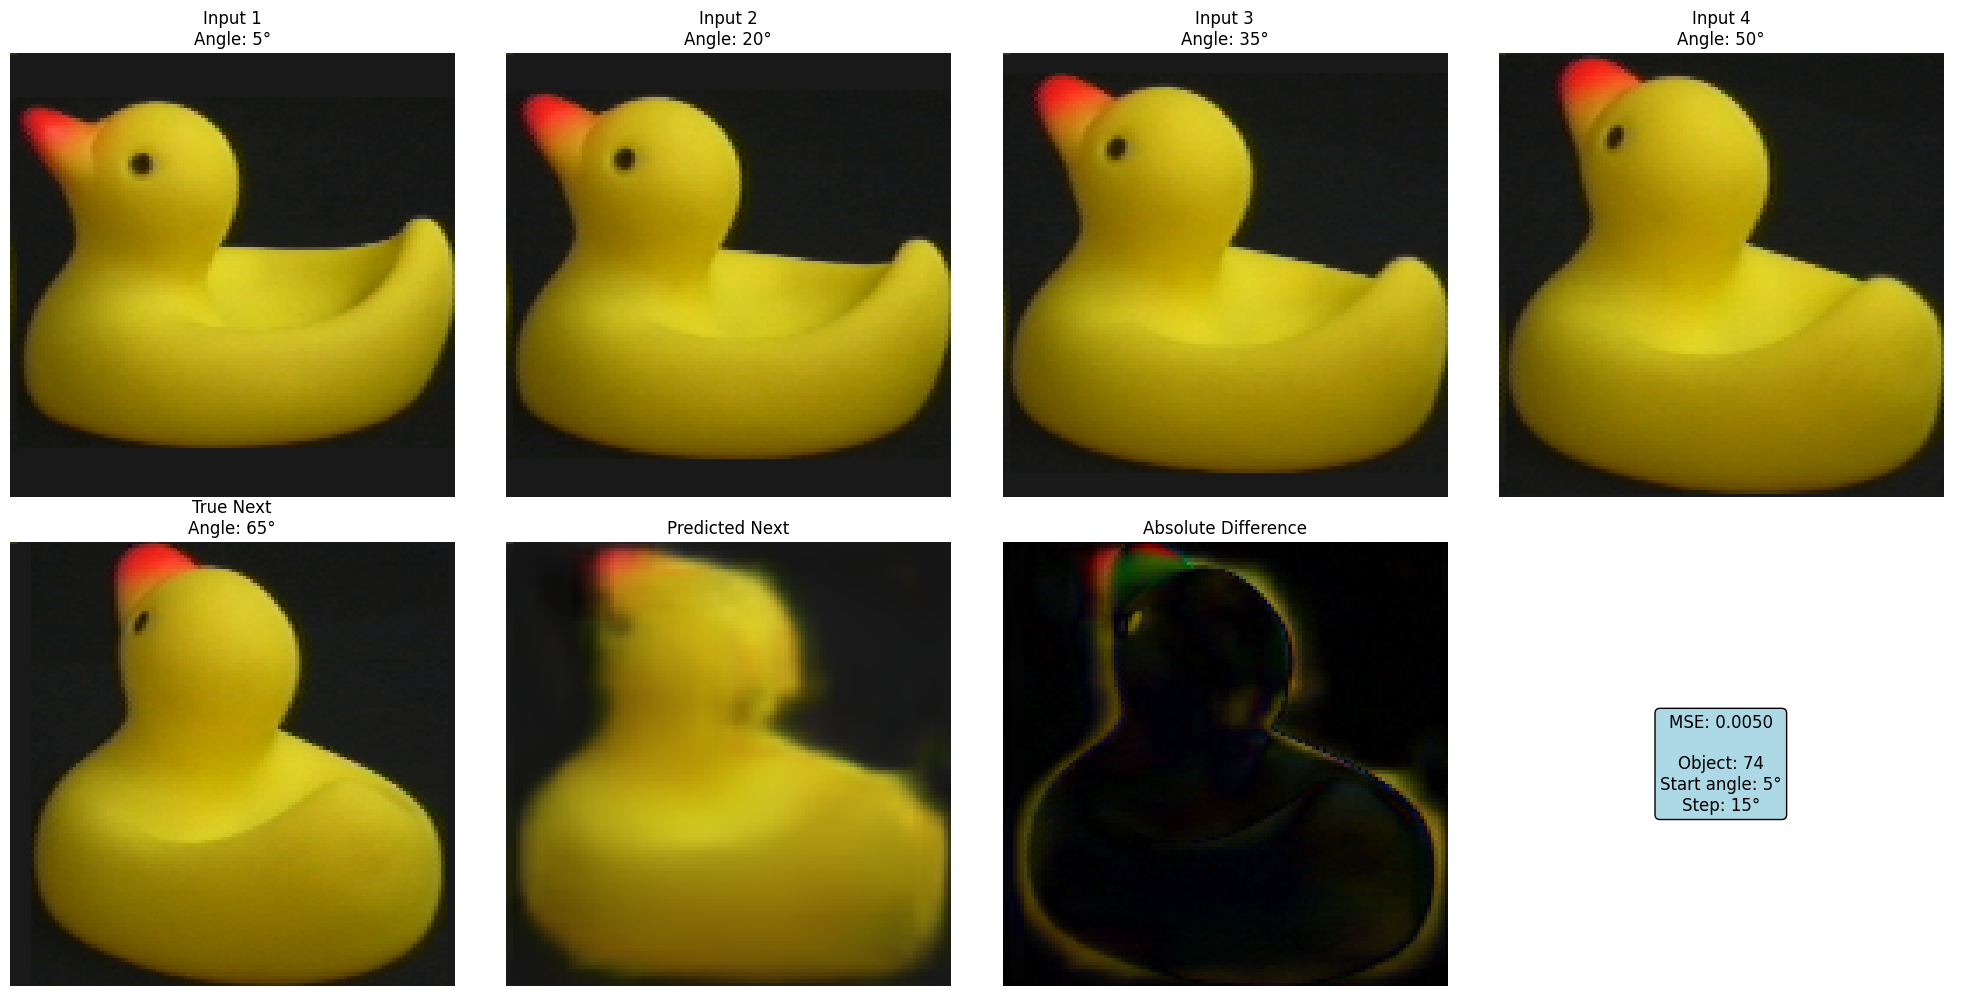

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


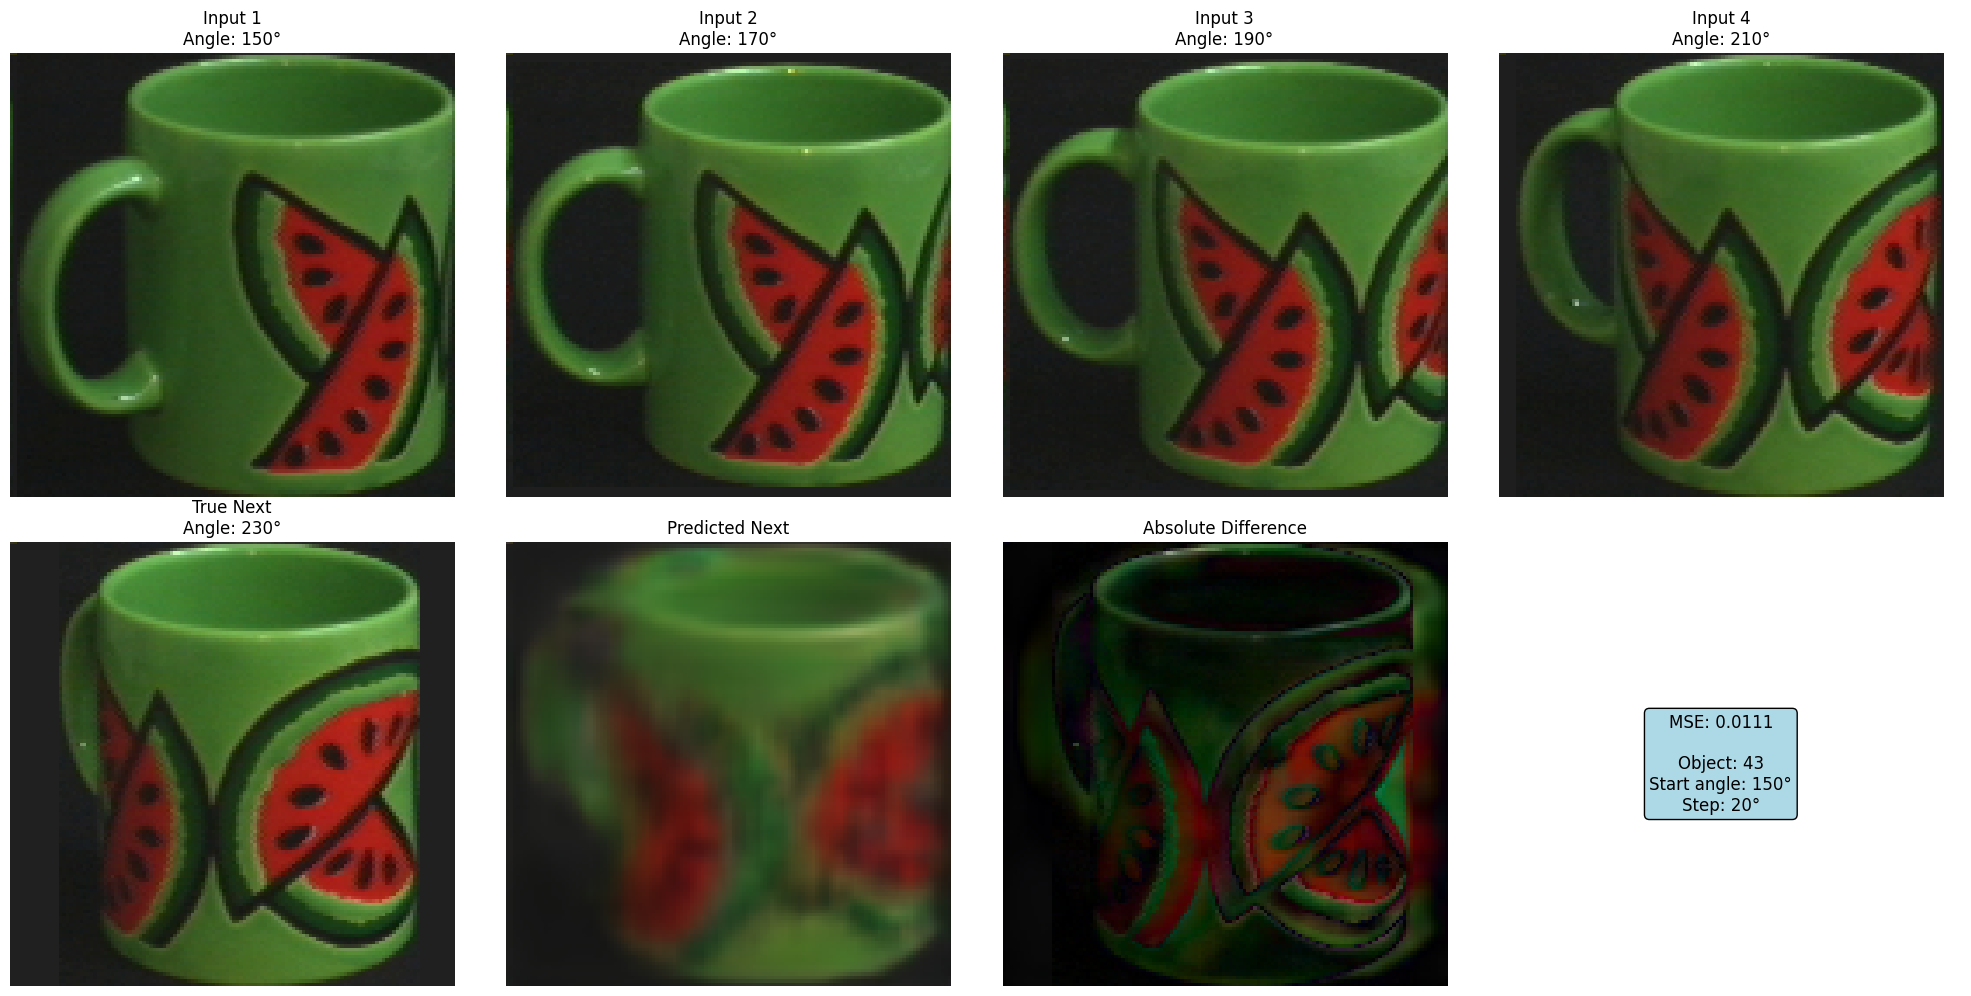

In [7]:
    # Visualizar una predicción
    predictor.visualize_prediction(obj_num=predictor.validation_objects[0], start_angle=45, step_ang=2)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[1], start_angle=5, step_ang=3)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[2], start_angle=150, step_ang=4)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


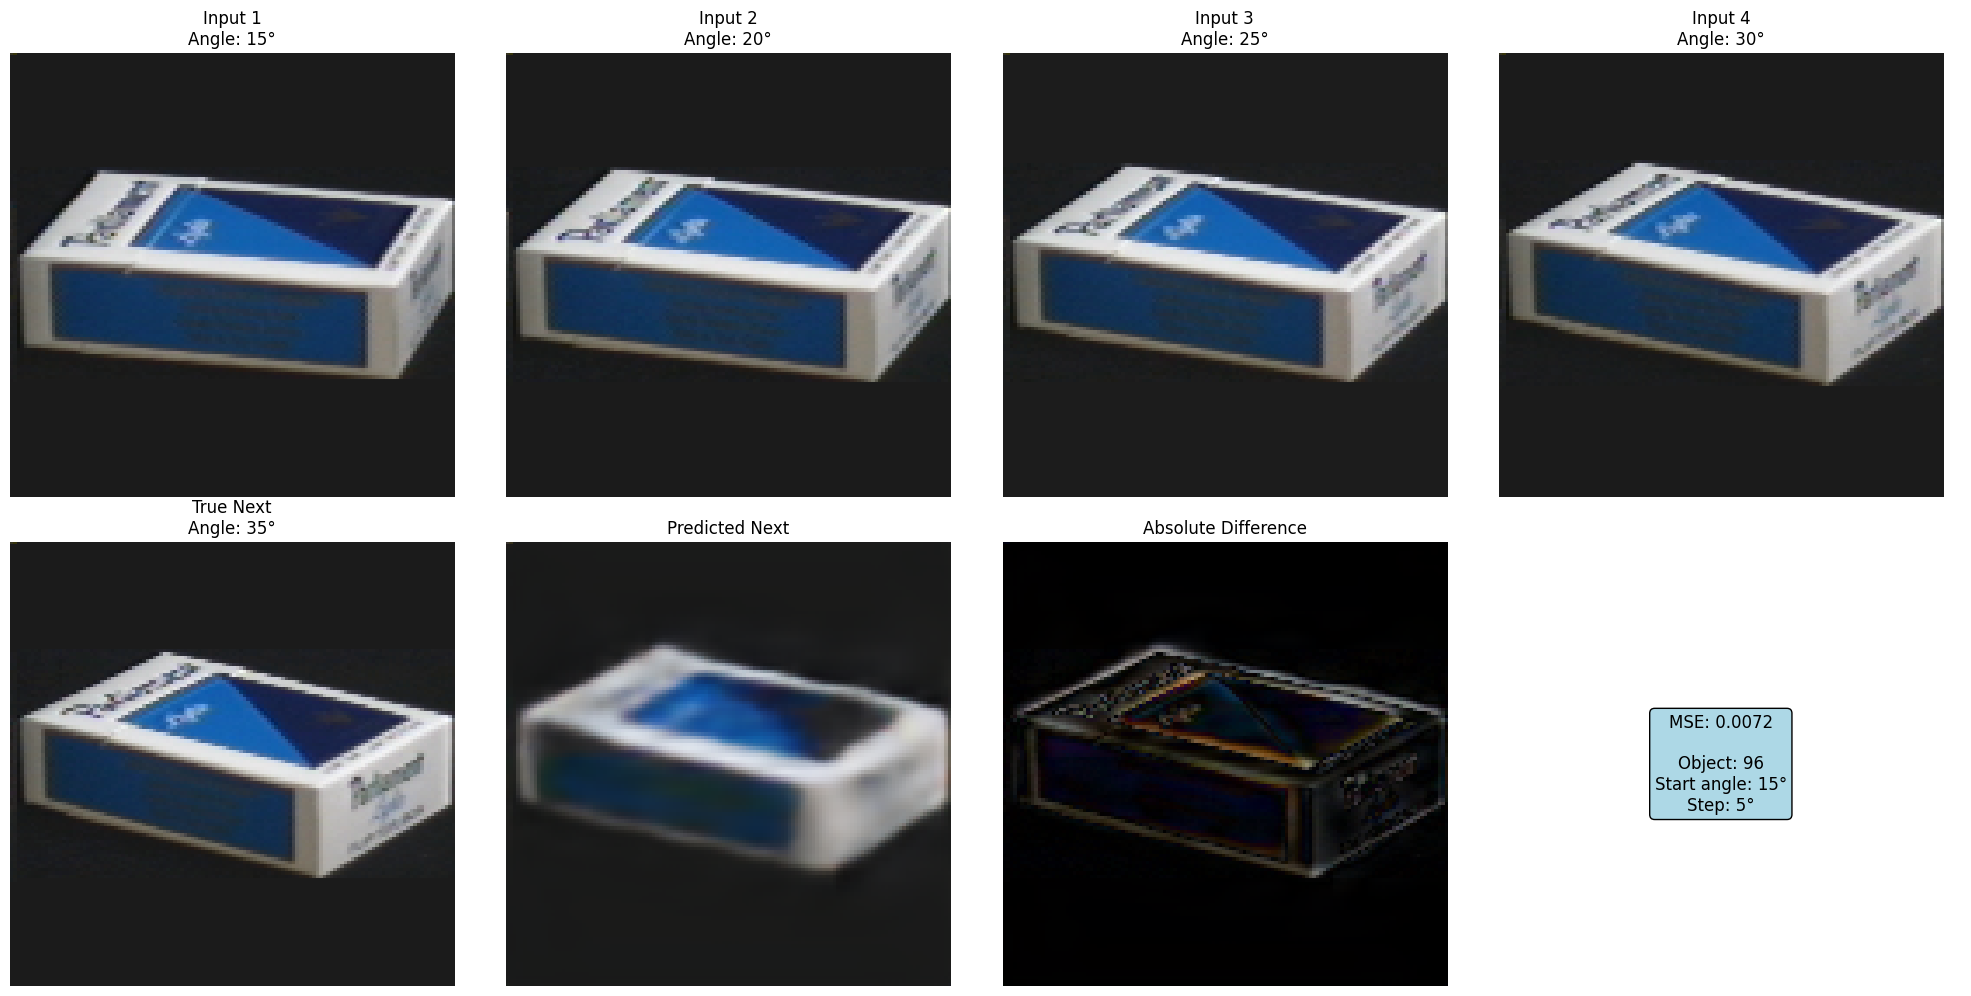

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


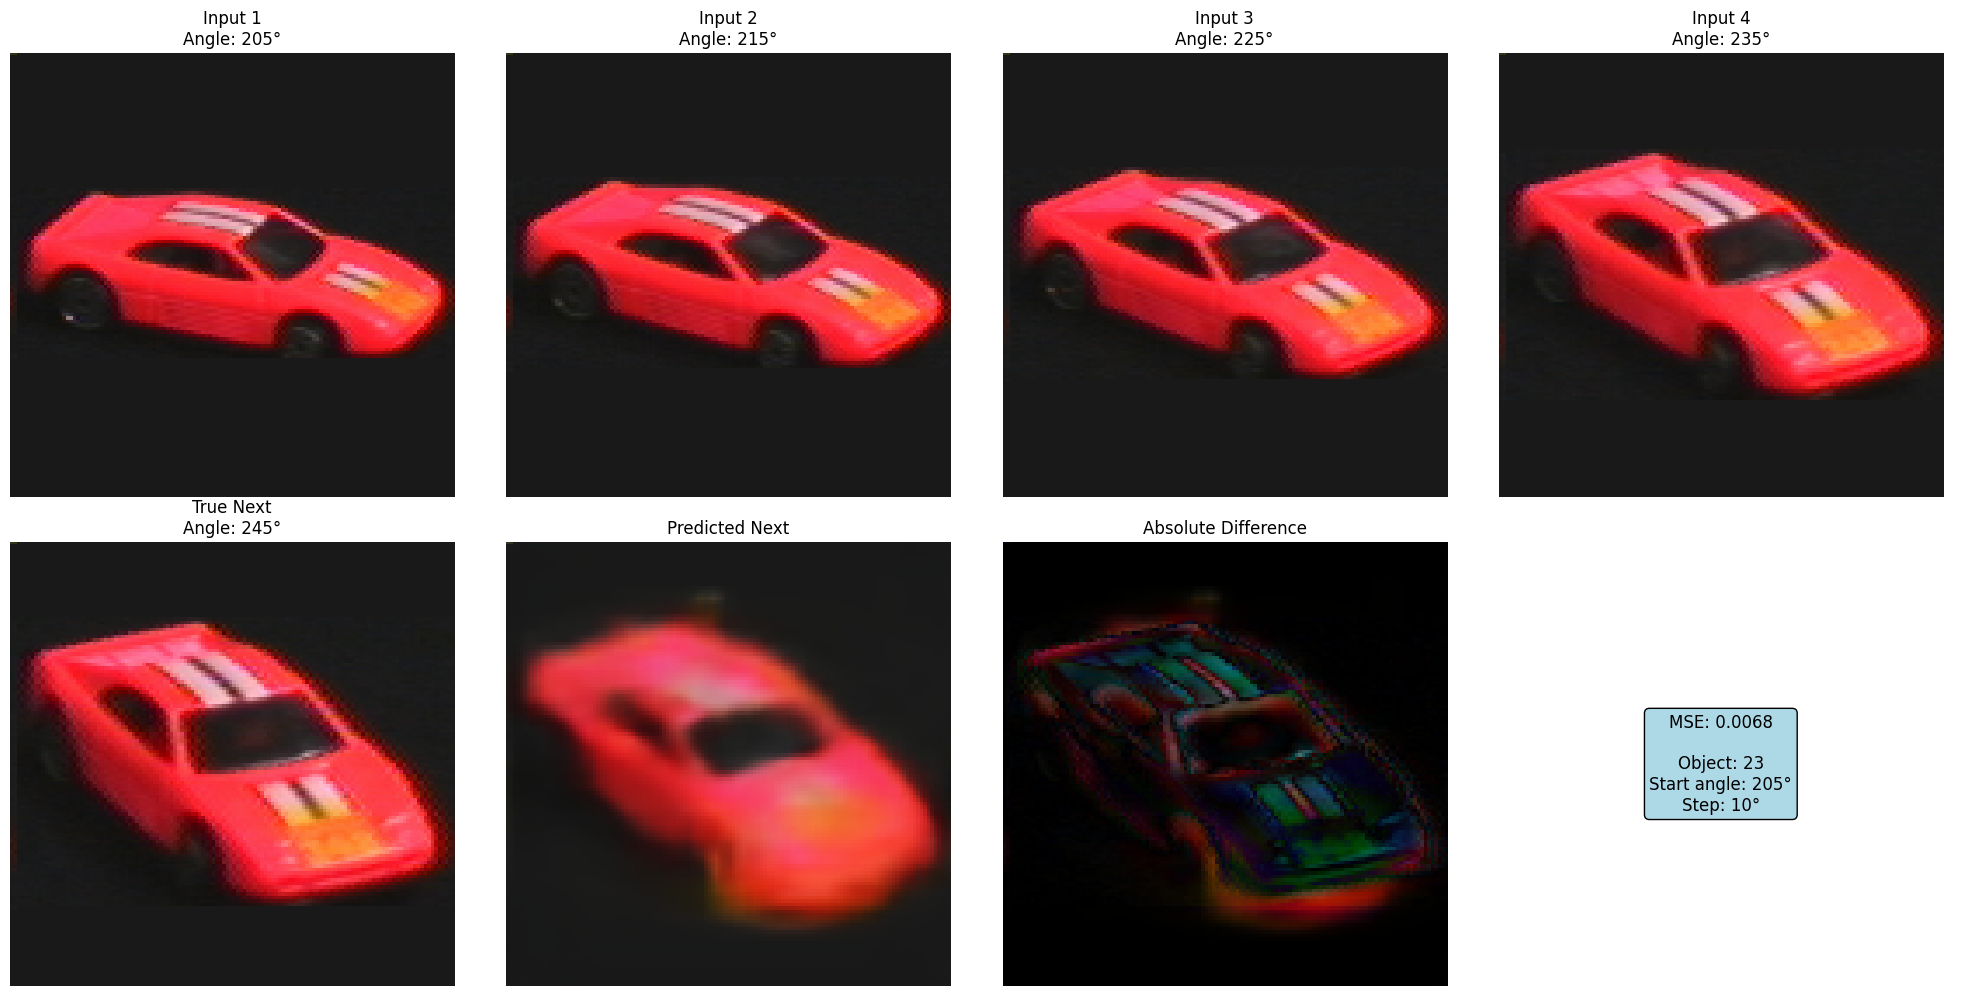

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


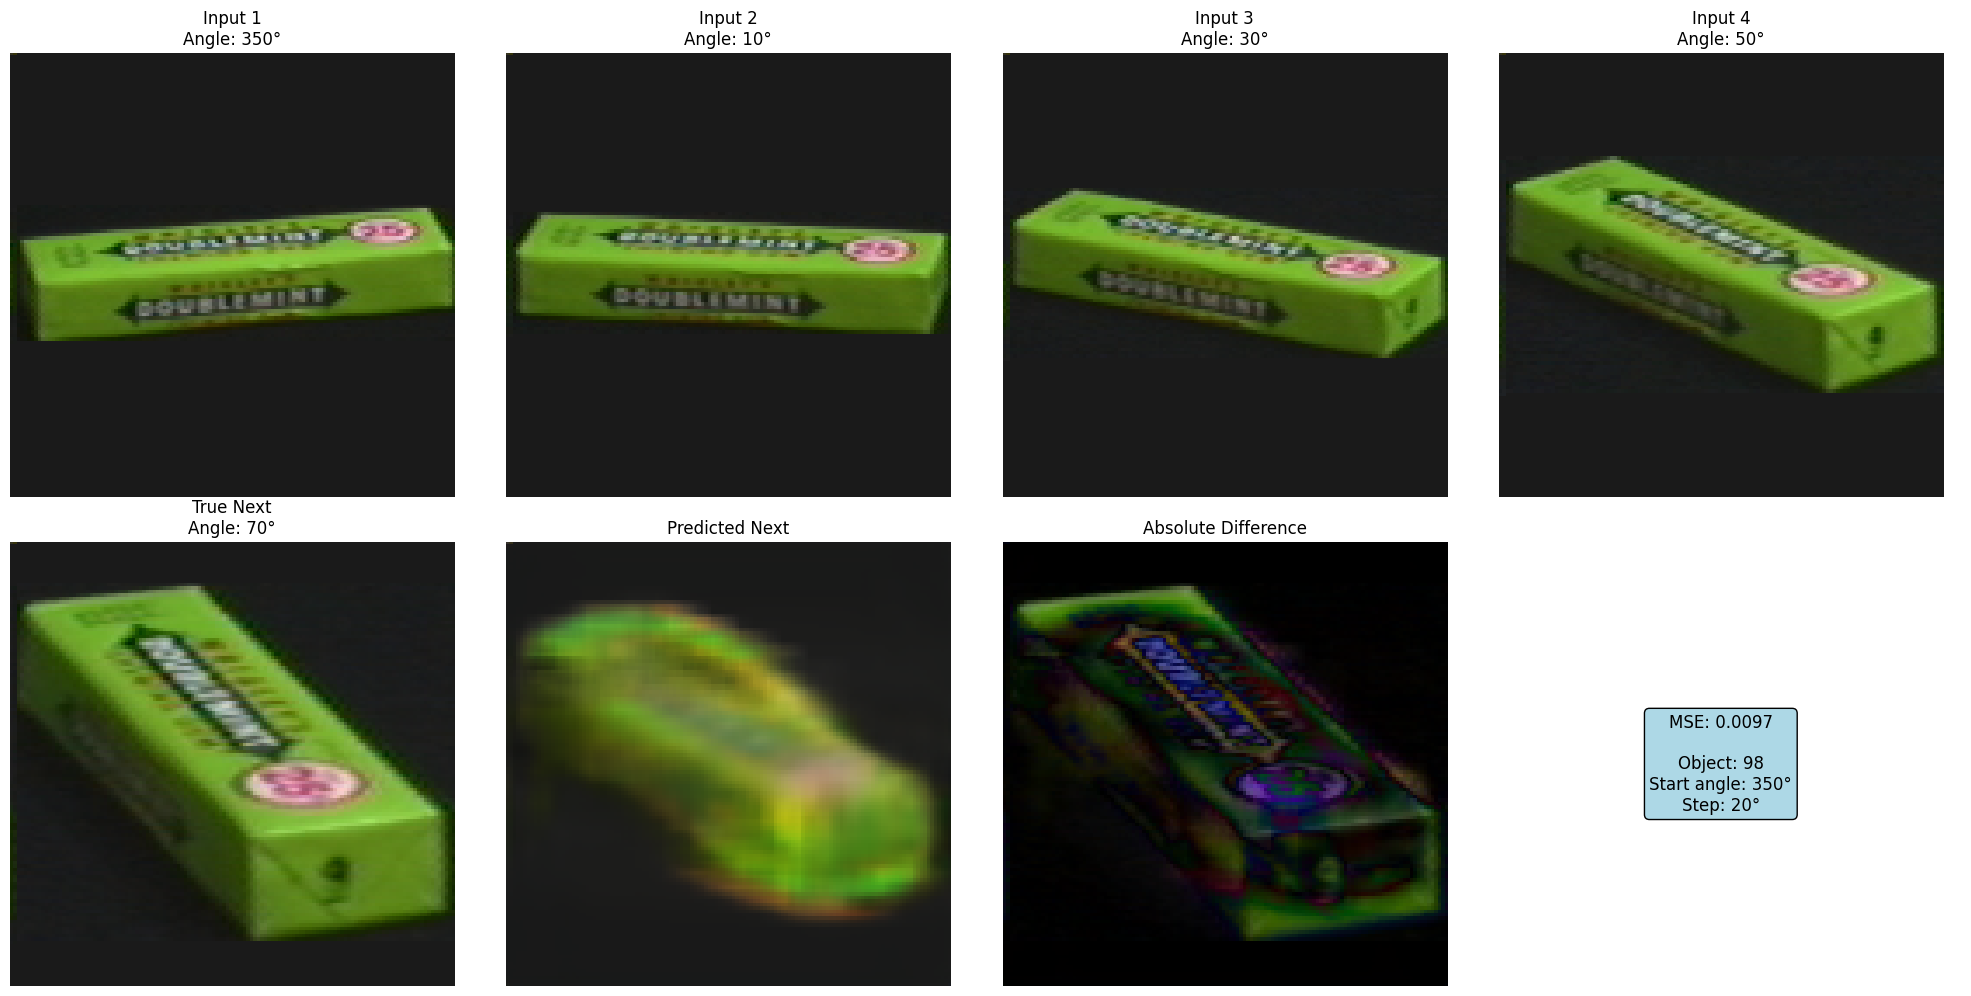

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


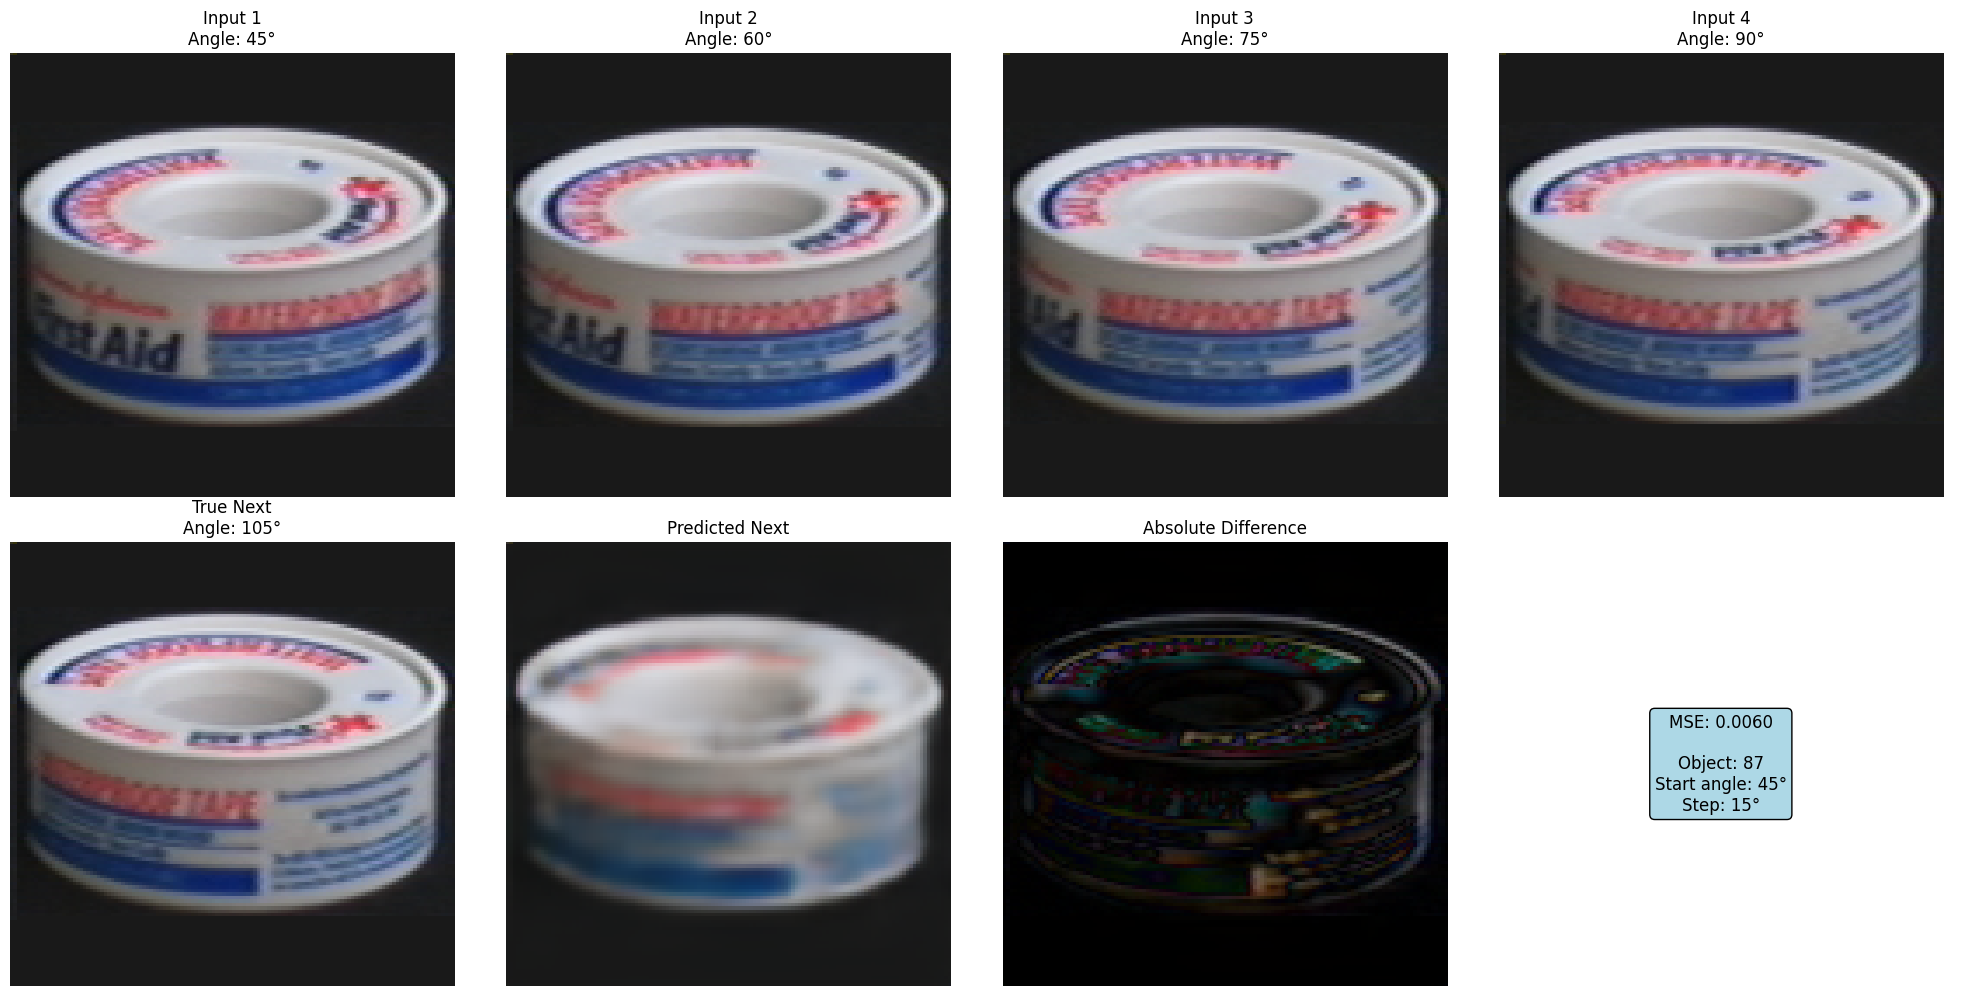

In [8]:
    predictor.visualize_prediction(obj_num=predictor.validation_objects[3], start_angle=15)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[4], start_angle=205, step_ang=2)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[5], start_angle=350, step_ang=4)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[6], start_angle=45, step_ang=3)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


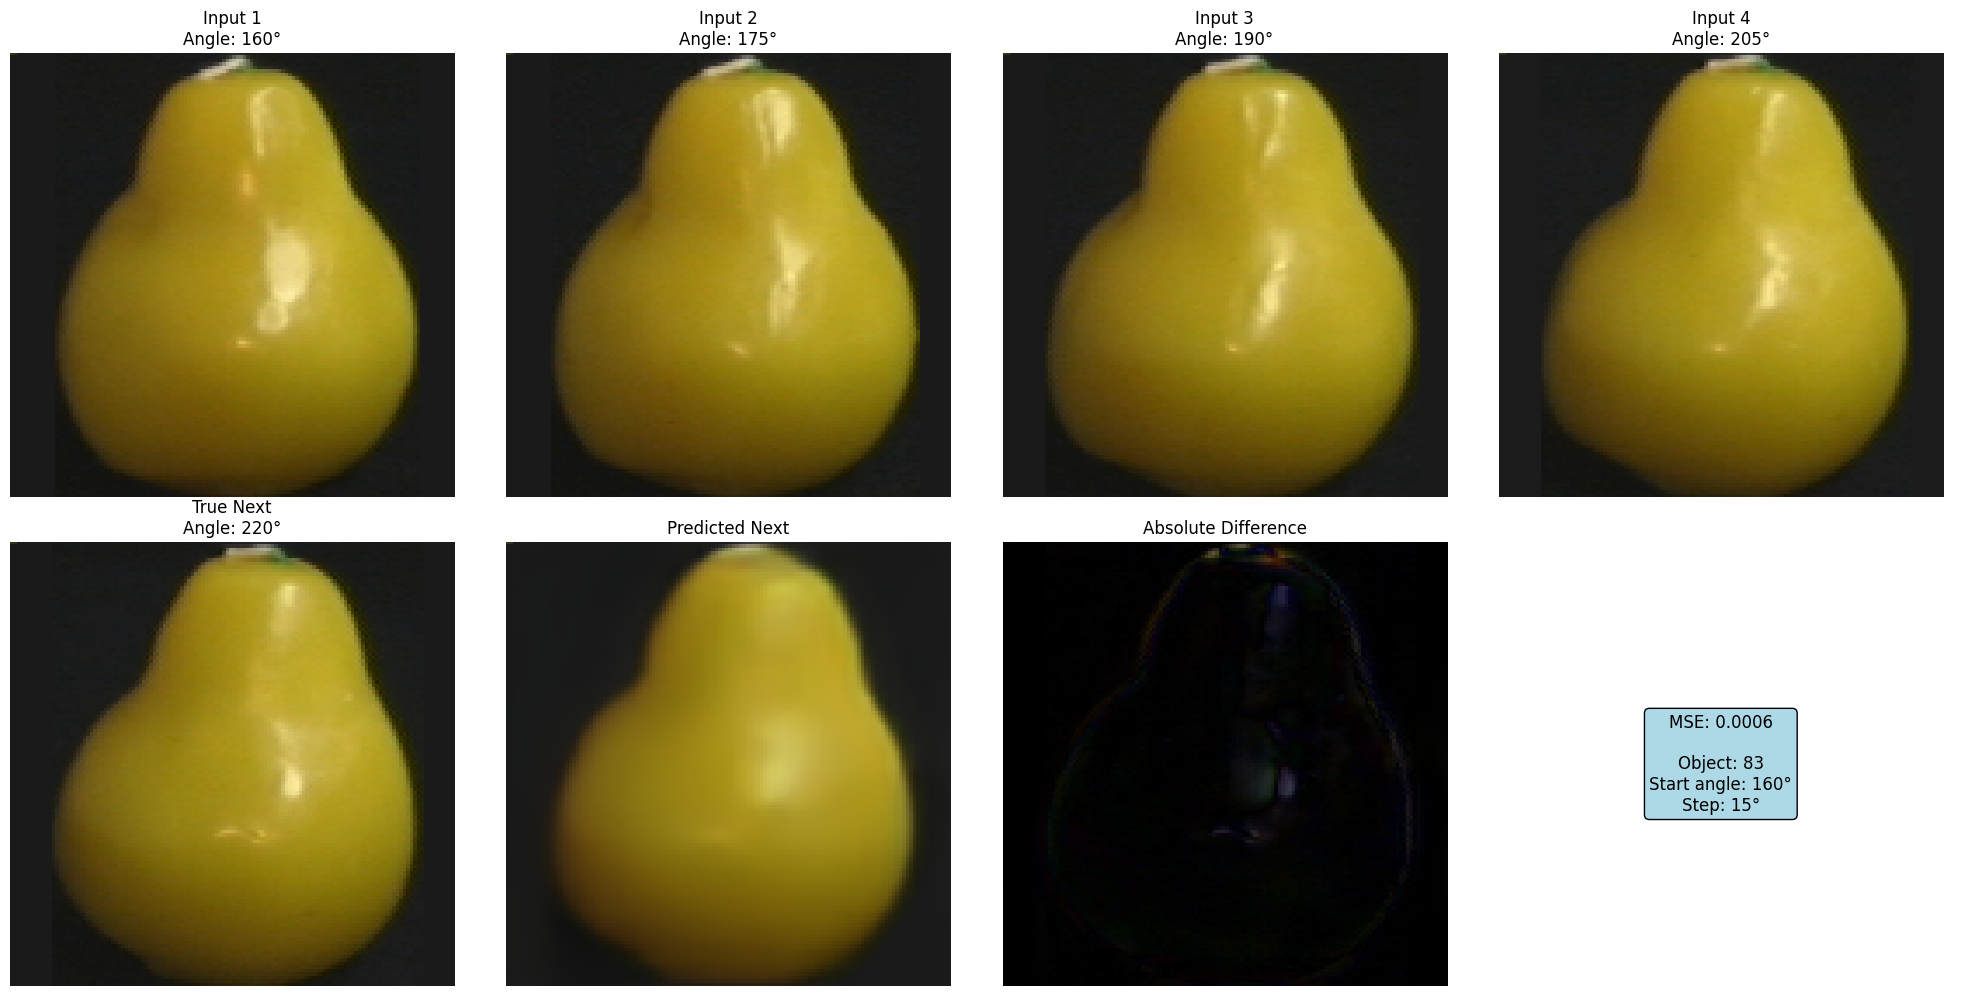

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


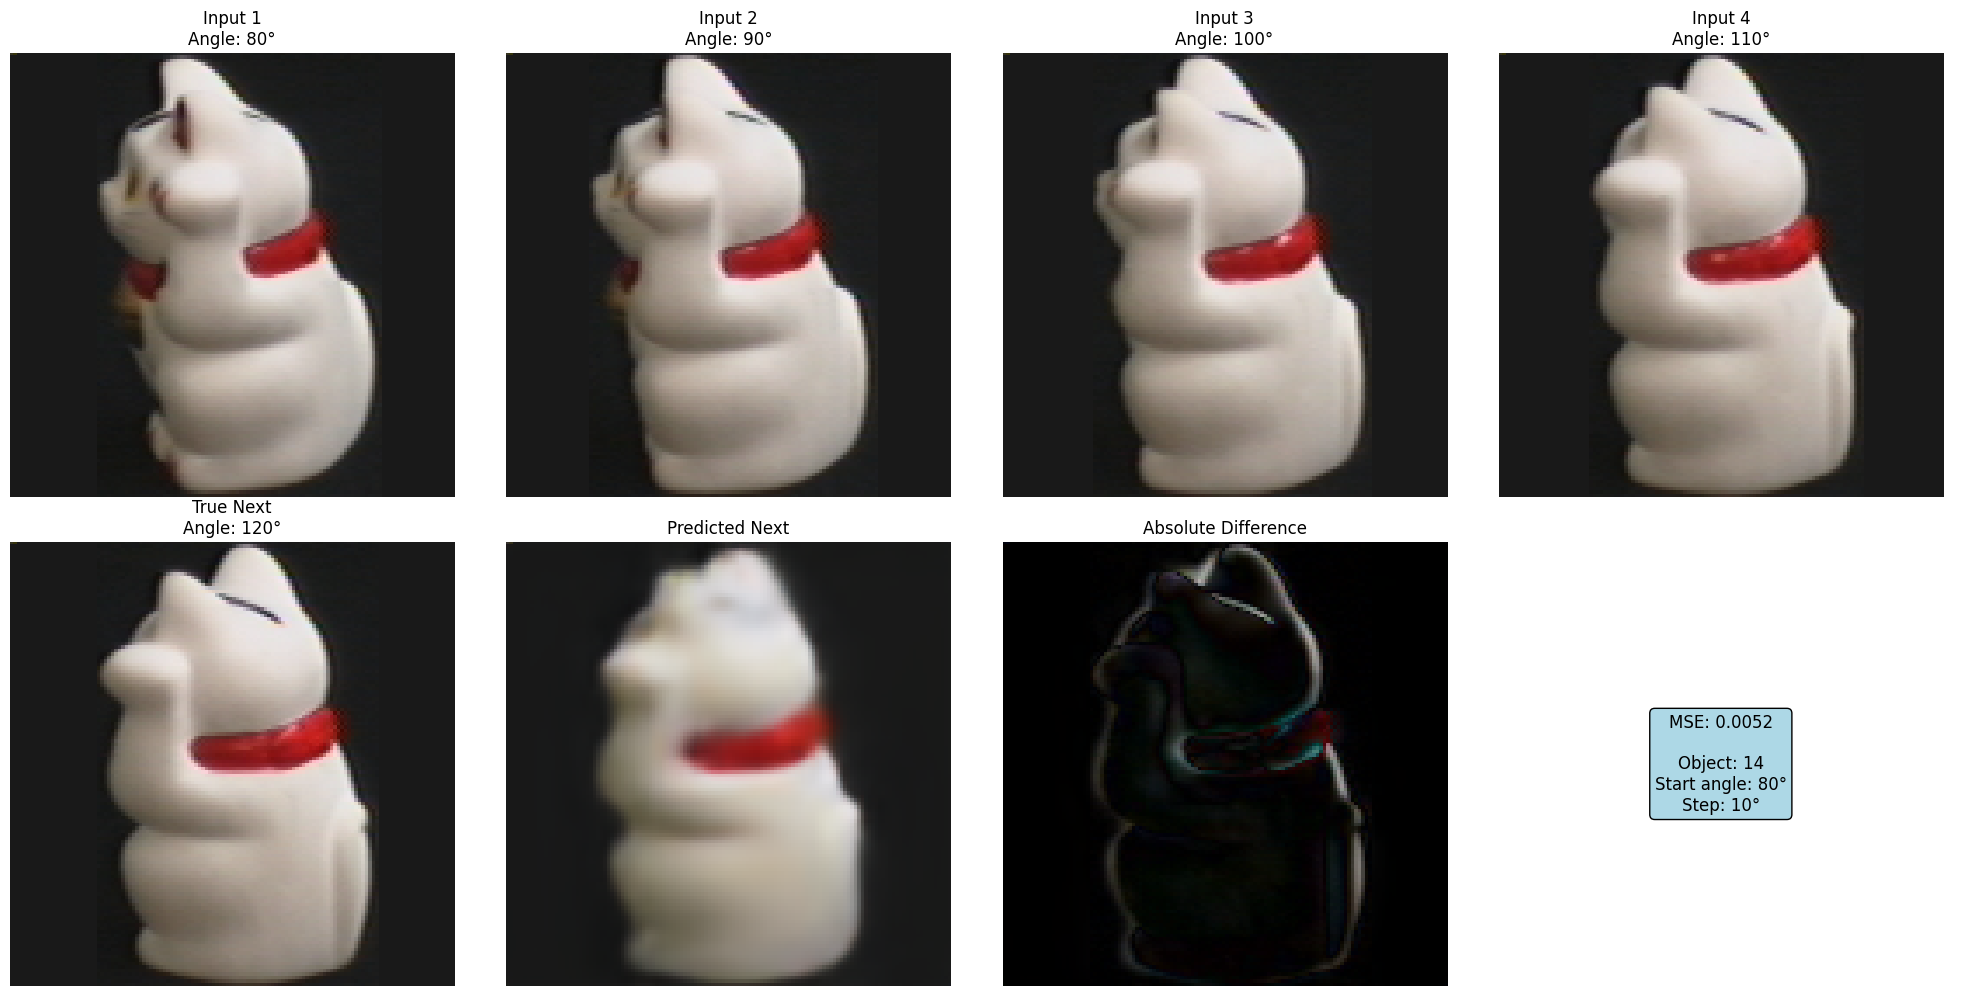

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


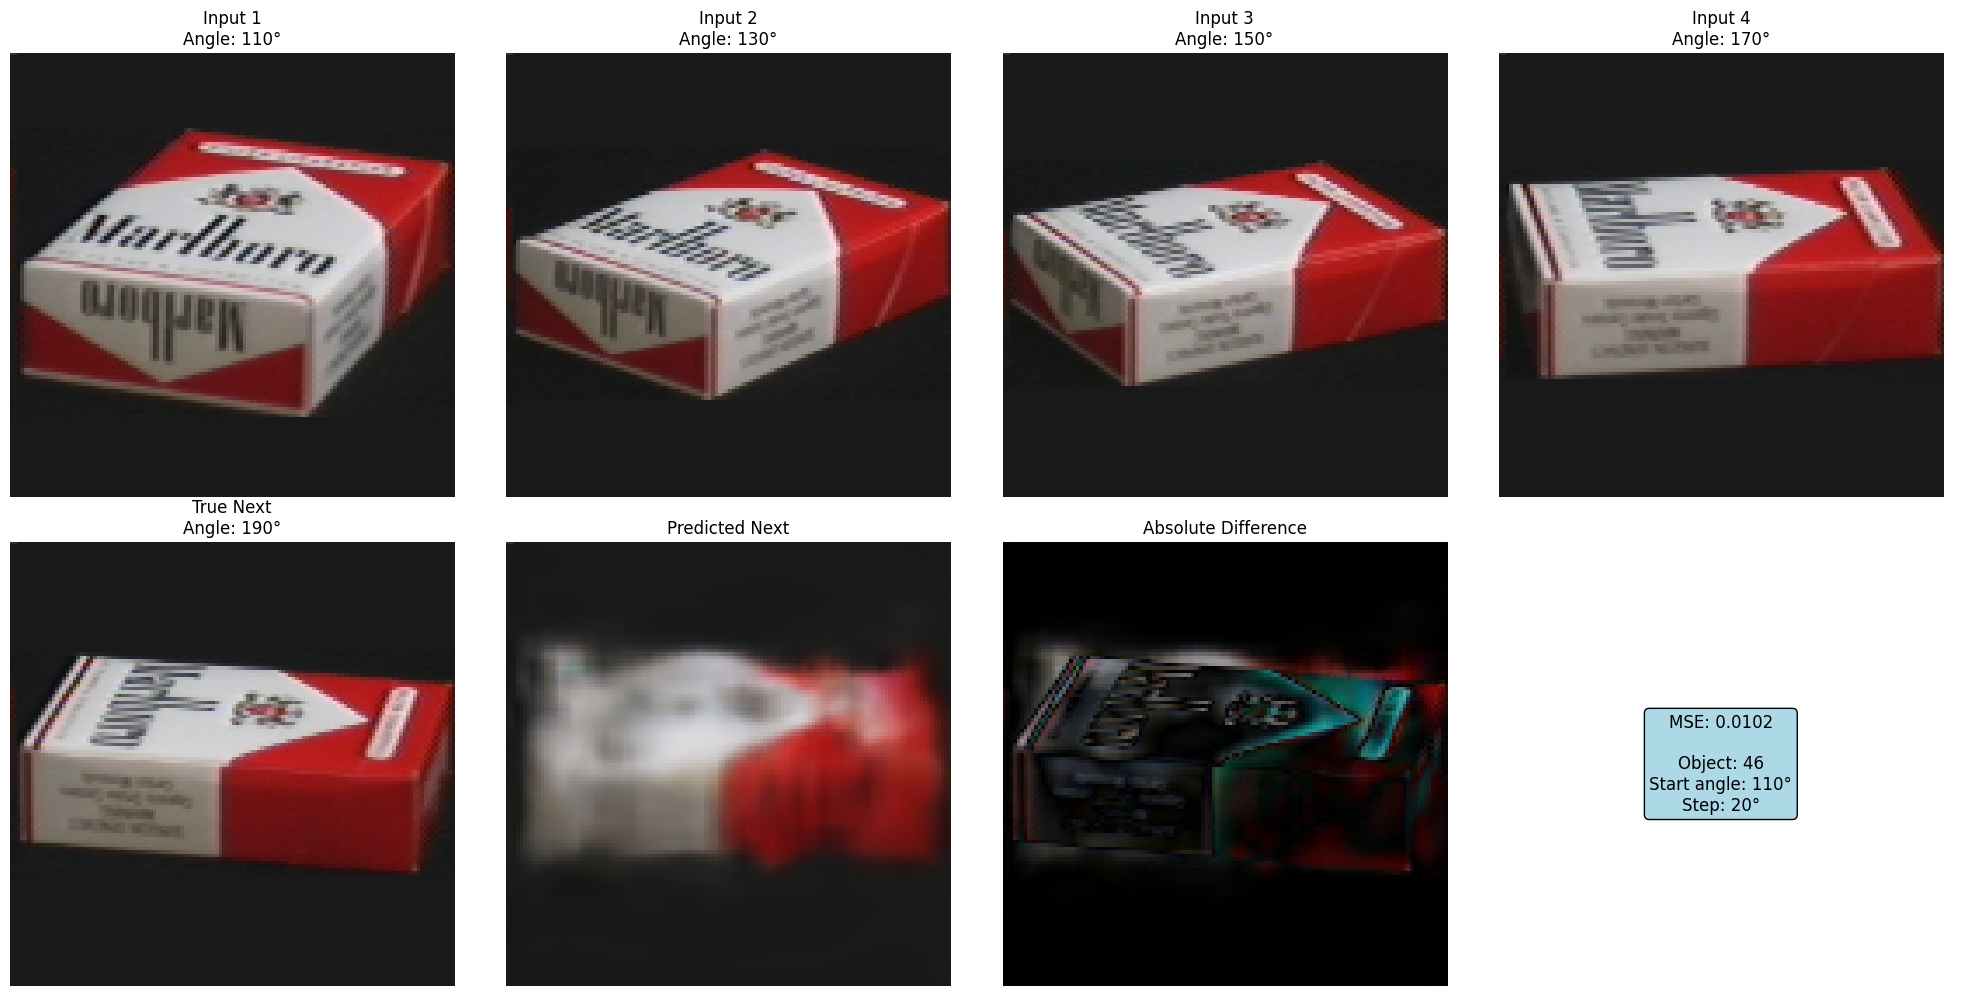

In [9]:
    predictor.visualize_prediction(obj_num=predictor.validation_objects[7], start_angle=160, step_ang=3)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[8], start_angle=80, step_ang=2)
    predictor.visualize_prediction(obj_num=predictor.validation_objects[9], start_angle=110, step_ang=4)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


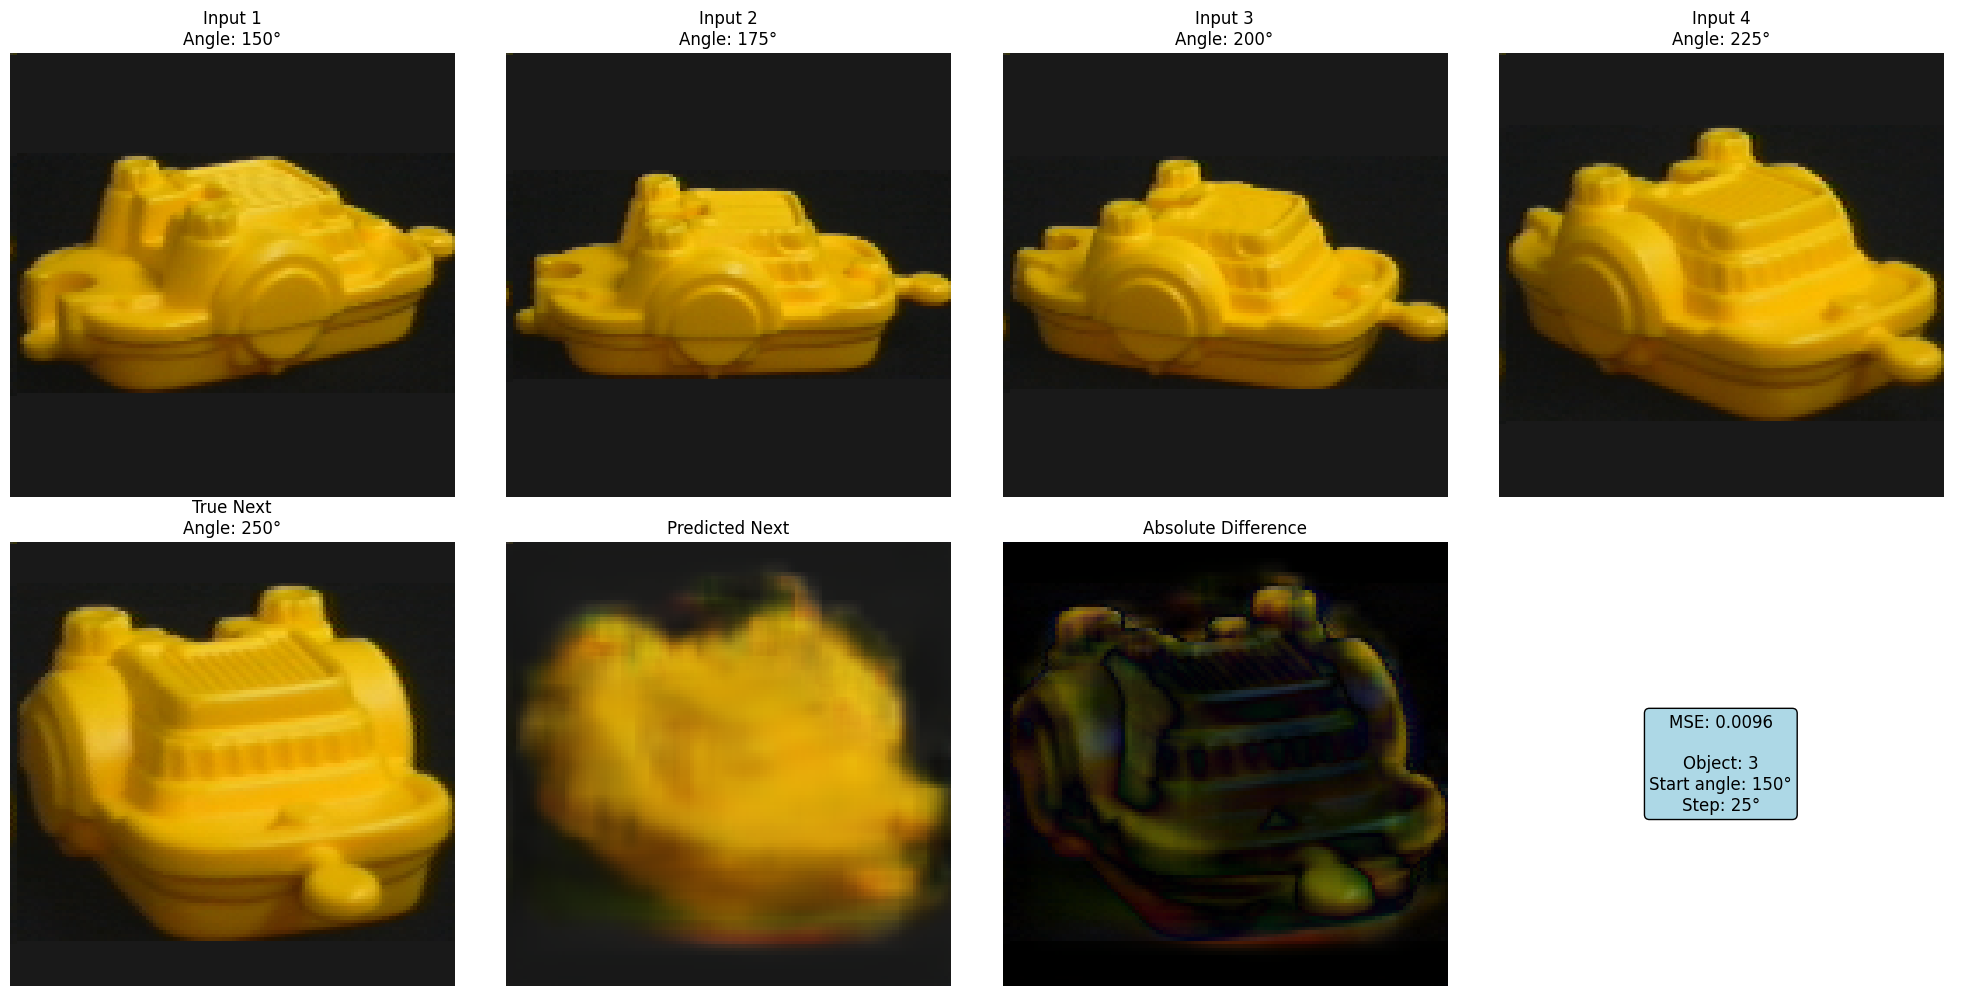

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


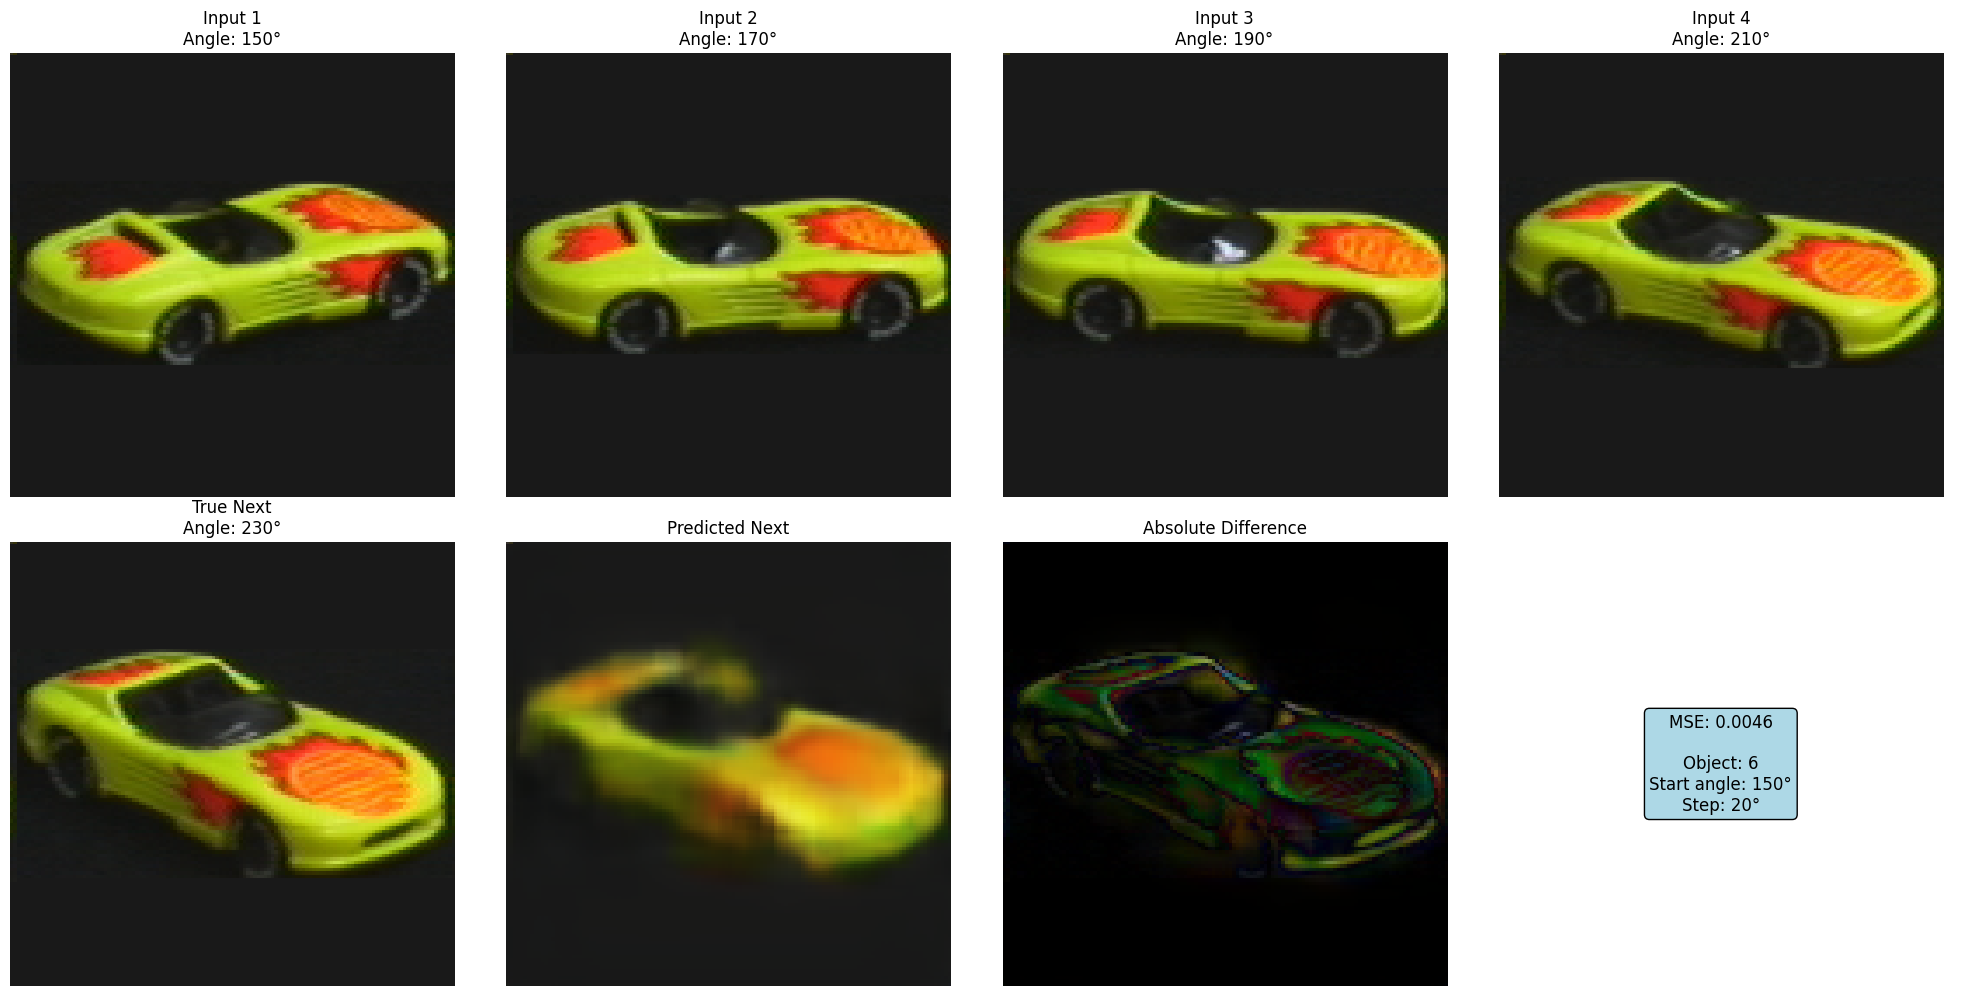

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


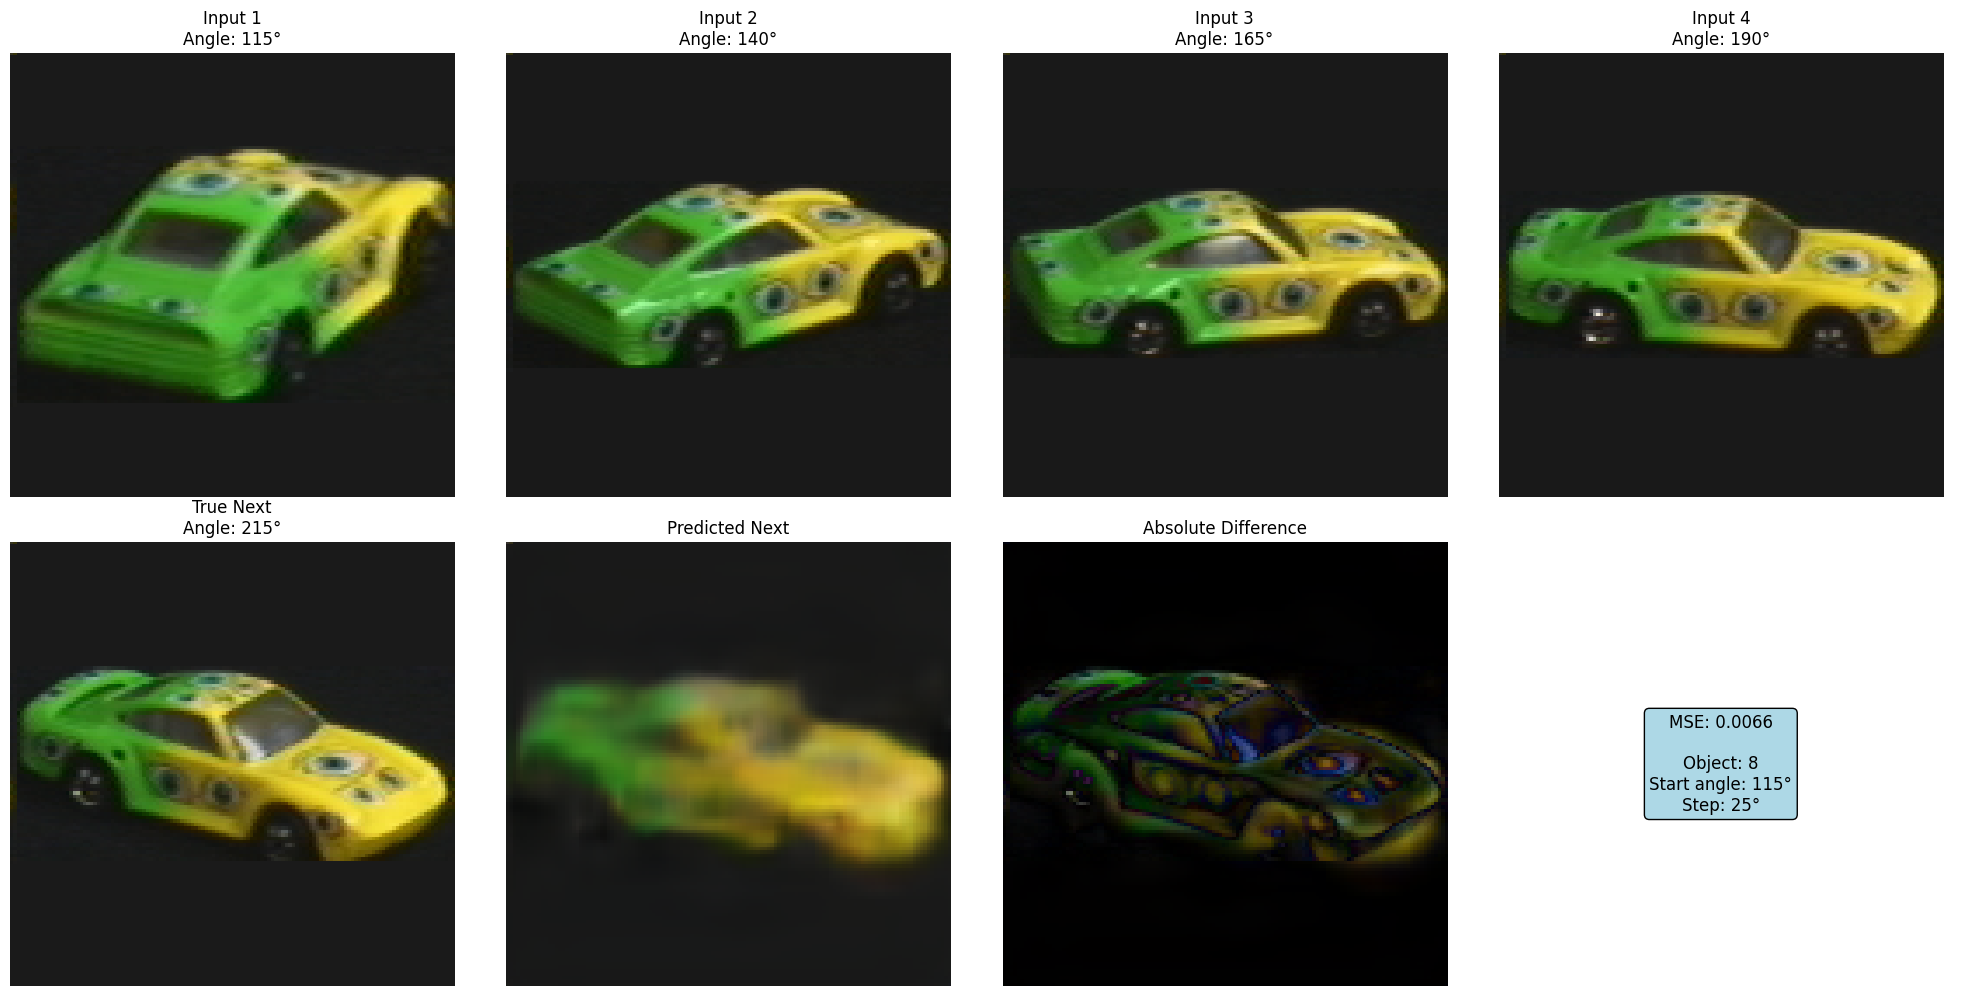

In [10]:
predictor.visualize_prediction(obj_num=predictor.train_objects[2], start_angle=150, step_ang=5)
predictor.visualize_prediction(obj_num=predictor.train_objects[5], start_angle=150, step_ang=4)
predictor.visualize_prediction(obj_num=predictor.train_objects[7], start_angle=115, step_ang=5)